# What are the most demanded skills for the top 3 most popular data roles?

**Methodology**

1. Clean-up skill column
2. Calculate the number of demanded skill based on 3 main roles
3. Modify to percent
4. Plot final findings

### Import Libraries and Data

In [9]:
import pandas as pd 
import matplotlib.pyplot as plt
from datasets import load_dataset
import seaborn as sns
import ast
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

### Filter Data for the United States

In [10]:
df_US = df[df['job_country'] == 'United States']

### Explode Skills

In [11]:
df_US = df_US.explode('job_skills')

### Aggregate Demanded Skills by Size Function

In [12]:
df_skill = df_US.groupby(['job_title_short', 'job_skills']).size()
df_skill = df_skill.reset_index(name = 'skill_count')
df_skill.sort_values(by = 'skill_count', ascending = False, inplace = True)
df_skill

,job_title_short,job_skills,skill_count
886,Data Scientist,python,42379
472,Data Analyst,sql,34452
921,Data Scientist,sql,30034
351,Data Analyst,excel,27519
890,Data Scientist,r,26022
...,...,...,...
1103,Machine Learning Engineer,sqlite,1
1244,Senior Data Analyst,react.js,1
1198,Senior Data Analyst,laravel,1
35,Business Analyst,dplyr,1


### Plot for 3 Data Roles

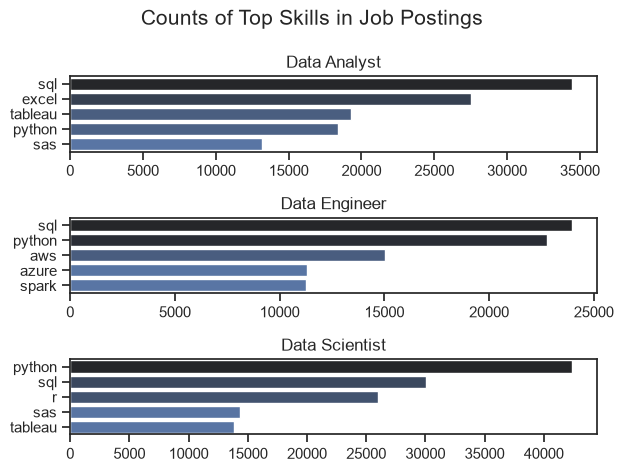

In [13]:
job_list = ['Data Analyst', 'Data Engineer', 'Data Scientist']
fig, ax = plt.subplots(3, 1)
sns.set_theme(style='ticks')
for i, job in enumerate(job_list):
    df_plot = df_skill[df_skill['job_title_short'] == job].head(5)
    sns.barplot(data = df_plot, x = 'skill_count', y = 'job_skills', ax = ax[i], hue = 'skill_count', palette = 'dark:b_r')
    ax[i].set_title(job)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
fig.suptitle('Counts of Top Skills in Job Postings', fontsize = 15)
fig.tight_layout()

### Calculate Percentage of Skill_count and Plot

In [ ]:
#Count sum of the number of postings
df_job = df_US['job_title_short'].value_counts().reset_index(name = 'job_total')
df_percent =pd.merge(df_skill, df_job,how = 'left', on = 'job_title_short')

#Create percent column from skill_count and job-total
df_percent['skill_percent'] = 100 * (df_percent['skill_count']/df_percent['job_total'])
df_percent

,job_title_short,job_skills,skill_count,job_total,skill_percent
0,Data Scientist,python,42379,322290,13.149338
1,Data Analyst,sql,34452,254289,13.548364
2,Data Scientist,sql,30034,322290,9.318936
3,Data Analyst,excel,27519,254289,10.821939
4,Data Scientist,r,26022,322290,8.074095
...,...,...,...,...,...
1865,Machine Learning Engineer,sqlite,1,5517,0.018126
1866,Senior Data Analyst,react.js,1,53025,0.001886
1867,Senior Data Analyst,laravel,1,53025,0.001886
1868,Business Analyst,dplyr,1,26518,0.003771


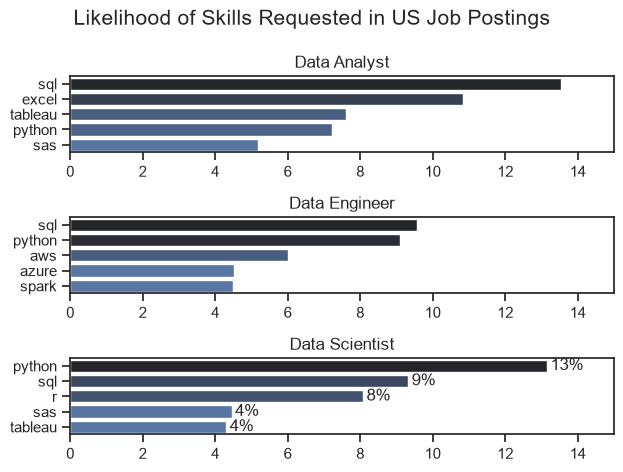

In [19]:
job_list = ['Data Analyst', 'Data Engineer', 'Data Scientist']
fig, ax = plt.subplots(3, 1)
sns.set_theme(style = 'ticks')
for i, job in enumerate(job_list):
    df_plot = df_percent[df_percent['job_title_short'] == job].head(5)
    sns.barplot(data = df_plot, x = 'skill_percent', y = 'job_skills', ax = ax[i], hue = 'skill_percent', palette = 'dark:b_r')
    ax[i].set_title(job)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].get_legend().remove()
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0,15)
fig.suptitle('Likelihood of Skills Requested in US Job Postings', fontsize = 15)

    # Using text in each columnn of a chart
for j, value in enumerate(df_plot['skill_percent']):
    ax[i].text(value+0.1, j, f'{value:.0f}%', va = 'center')

    #Set xaxis at the bottom of chart
if i != (len(job_list) - 1):
    ax[i].set_xticks([])

# Set the distance between 3 graph
fig.tight_layout(h_pad=1)
plt.show()